# Simulación de Monte Carlo — Efecto del número de asesores sobre las rutas

**Proyecto:** balanceo del rutero de preventa (Distribuidora Hijos de León — Boyacá y Cundinamarca)
**Base:** `base_clientes_limpia.csv` (único insumo; no depende de archivos crudos)
**Modelo de referencia:** `Modelo_Ruteo_KMeans_NN_ACO_11.10.ipynb` (K-Means + Nearest Neighbor / ACO)

## Objetivo
Responder a la pregunta de decisión: **¿cuántos asesores conviene tener, dado su efecto sobre las rutas?**
Cada número de asesores $K \in \{5,6,\dots,24\}$ es una *estrategia* que genera su propia
estructura de territorios y rutas; sobre cada estrategia se simulan muchos escenarios bajo
incertidumbre (asistencia de clientes y tráfico) y se comparan las **distribuciones del costo total**.

## Metodología (estilo *MonteCarlo_Flota_Bicicletas_Unidad_1_Tema_3*)
1. **Capa estructural (determinista):** para cada $K$, los CDs reciben asesores proporcionales a su
   volumen de clientes; los clientes del CD se agrupan en $k_c$ territorios (K-Means) y cada territorio
   se parte en sub-rutas (≤ 45 clientes) secuenciadas por **Nearest Neighbor** desde el depósito del CD.
2. **Capa estocástica:** por escenario, cada cliente programado **asiste con probabilidad $p$** (Bernoulli)
   y el **tiempo de viaje se multiplica por un factor de tráfico** (Triangular). Los no-asistentes se
   "saltan" en la secuencia (la ruta se acorta exactamente, vía matrices de distancia).
3. **Métrica de decisión:** costo total por ciclo = fijo de asesores + km + horas (viaje y servicio),
   con *common random numbers* (los mismos escenarios para todas las estrategias) para comparación pareada.

## Restricciones de negocio heredadas del modelo
- Máximo **45 visitas por sub-ruta/día** (`CAP`).
- Ventanas horarias por categoría: tiendas y bodegas en el slot de la mañana, entretemiento en el de la tarde.
- Cada CD debe estar cubierto ⇒ **mínimo 1 asesor por CD** ⇒ $K \ge 5$.

> **Nota sobre ACO:** el modelo de ruteo mostró que ACO mejora al NN ~2,3 %. Aquí se usa el NN por
> velocidad (segundos vs. minutos), de modo que todas las estrategias se comparan con el mismo motor.

In [1]:
# ============================ PARÁMETROS GLOBALES ============================
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.cluster import KMeans

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")

SEMILLA = 2026                      # semilla maestra (reproducibilidad)
N_SIM    = 1000                     # escenarios por estrategia (verificar convergencia)
CAP      = 45                       # máximo de visitas por sub-ruta/día (igual al modelo de ruteo)
UMBRAL_CD = 20                      # mínimo de clientes para que un CD sea rutable

# --- Incertidumbre (variables del escenario) ---
P_ASIST = 0.85                      # prob. de asistencia de un cliente programado
TRI_MIN, TRI_MOD, TRI_MAX = 0.7, 1.0, 1.4   # factor de tráfico sobre el tiempo de viaje

# --- Operación y costos (SUPUESTOS del equipo, calibrables con la empresa) ---
# El periodo simulado es un "ciclo de rutero" (≈ quincena); el costo fijo por asesor
# corresponde al ciclo (≈ mitad de un mensual).
VEL_BASE      = 30                  # km/h promedio sin tráfico
T_SERVICIO    = 12 / 60             # h por visita atendida (12 min)
COSTO_ASESOR  = 1_500_000           # COP/ciclo fijo por asesor (salario + vehículo)
COSTO_KM      = 1_200               # COP/km (combustible + mantenimiento)
COSTO_HORA    = 12_000              # COP/hora cargada (viaje + servicio)

# --- Estrategias ---
K_MIN, K_MAX = 5, 24                # se evalúa cada entero del rango (20 estrategias)

print(f"Semilla: {SEMILLA} | N_SIM: {N_SIM} | Capacidad: {CAP} | Estrategias: K={K_MIN}..{K_MAX}")

Semilla: 2026 | N_SIM: 1000 | Capacidad: 45 | Estrategias: K=5..24


## 1. Carga y universo de ruteo

Mismo embudo que el modelo de ruteo para que los resultados sean comparables:
solo clientes **activos**, **con visita asignada** y con **coordenadas válidas**.
Se exige un mínimo de `UMBRAL_CD` clientes por CD (los CDs diminutos no justifican un asesor propio).

In [2]:
# ------------------------- Carga (solo base limpia) -------------------------
def cargar_base(nombre):
    if IN_COLAB:
        from google.colab import files
        subido = files.upload()
        return pd.read_csv(list(subido.keys())[0], encoding="utf-8-sig")
    for c in [nombre, os.path.join("data", nombre)]:
        if os.path.exists(c):
            return pd.read_csv(c, encoding="utf-8-sig")
    raise FileNotFoundError(f"No encontré {nombre}. Cópialo en la raíz o en data/.")

try:
    IN_COLAB
except NameError:
    IN_COLAB = False

df = cargar_base("base_clientes_limpia.csv")
print("Base cargada:", df.shape, "| Nombre CD presente:", "Nombre CD" in df.columns)

# ------------------------------ Embudo ---------------------------------------
embudo = [("Base limpia completa", len(df))]
df = df[df["Supervisor"].astype(str).str.strip().ne("SIN_ASIGNAR")].copy()
embudo.append(("Con asesor asignado", len(df)))
df = df[df["activo"] == 1].copy()
embudo.append(("Solo activos", len(df)))
df = df[df["visitas_mes_rep"] > 0].copy()
embudo.append(("Con visita asignada (visitas_mes_rep>0)", len(df)))
dentro = df["Latitud"].between(3.0, 6.2) & df["Longitud"].between(-77.0, -72.5)
df = df[dentro].copy()
embudo.append(("Con coordenadas válidas", len(df)))

n_cd = df.groupby("Cod CD")["CodigoCliente"].size()
cds_ok = n_cd[n_cd >= UMBRAL_CD].index
df = df[df["Cod CD"].isin(cds_ok)].copy()
embudo.append((f"CDs con >= {UMBRAL_CD} clientes", len(df)))

emb = pd.DataFrame(embudo, columns=["paso", "filas"])
emb["eliminadas"] = emb["filas"].shift(1).fillna(0) - emb["filas"]
display(emb.style.format({"filas": "{:,}", "eliminadas": "{:,}"}))
print(f"\nUniverso de ruteo: {len(df):,} clientes en {df['Cod CD'].nunique()} CDs")

Base cargada: (16560, 48) | Nombre CD presente: True


,paso,filas,eliminadas
0,Base limpia completa,"16,560","-16,560.0"
1,Con asesor asignado,"16,560",0.0
2,Solo activos,"14,796","1,764.0"
3,Con visita asignada (visitas_mes_rep>0),"14,757",39.0
4,Con coordenadas válidas,"14,757",0.0
5,CDs con >= 20 clientes,"14,750",7.0



Universo de ruteo: 14,750 clientes en 5 CDs


## 2. Proyección geográfica, ventanas y depósitos por CD

El depósito de cada CD se aproxima con el **centroide de sus clientes** (la base no trae las
coordenadas exactas de los CDs), igual que en el modelo de ruteo. Todas las sub-rutas de un CD
salen de ese mismo depósito.

In [3]:
R_TIERRA = 6371.0  # km

# Ventanas horarias: conjunto de slots permitidos por categoría
VENTANAS = {"Tiendas": {0}, "Bodegas": {0}, "Entretenimiento": {2}, "Otros": {0, 1, 2}}
df["slots"] = df["CategoriaActividad"].map(lambda c: VENTANAS.get(c, {0, 1, 2}))

# Proyección equirrectangular a km (phi0 = latitud media del CD)
phi0 = np.radians(df.groupby("Cod CD")["Latitud"].transform("mean"))
df["x_km"] = R_TIERRA * np.radians(df["Longitud"]) * np.cos(phi0)
df["y_km"] = R_TIERRA * np.radians(df["Latitud"])

# Depósito por CD = centroide de sus clientes
dep = (df.groupby("Cod CD")
         .agg(dep_lat=("Latitud", "mean"), dep_lon=("Longitud", "mean"),
              n=("CodigoCliente", "size"), nombre=("Nombre CD", "first"))
         .reset_index()
         .sort_values("Cod CD")
         .reset_index(drop=True))
dep["n_rutas_min"] = np.ceil(dep["n"] / CAP).astype(int)

# Índice global de cliente (para la matriz de asistencia: mismo cliente ⇒ mismo escenario)
df = df.reset_index(drop=True)
df["_uid"] = np.arange(len(df))

display(dep.style.format({"dep_lat": "{:.4f}", "dep_lon": "{:.4f}", "n": "{:,}"}))
print("Sub-rutas mínimas por capacidad (referencia):", int(dep["n_rutas_min"].sum()))

,Cod CD,dep_lat,dep_lon,n,nombre,n_rutas_min
0,AV06,5.0028,-73.8657,"8,361",CD Tocancipá,186
1,AV42,5.3861,-73.3298,"2,609",CD OL de Tunja,58
2,AV59,4.9321,-73.8300,600,CD B2B Estadísticos MKP,14
3,AV61,5.0926,-73.3655,472,CD AV61,11
4,AV66,5.4601,-73.7947,"2,708",Chiquinquirá,61


Sub-rutas mínimas por capacidad (referencia): 330


## 3. Regla de asignación de asesores a CDs

Para un total de $K$ asesores, cada CD recibe al menos 1 y el resto se reparte
**proporcional a su número de clientes** (método de mayores restos).
La regla es determinista: la misma para todos los escenarios (es una decisión de estructura, no de azar).

In [4]:
def asignar_asesores(K, dep):
    """Reparte K asesores entre los CDs: mínimo 1 por CD, resto proporcional a clientes
    (método de mayores restos). Devuelve el vector de asesores por CD (orden de dep)."""
    k = len(dep)
    assert K >= k, f"K debe ser >= {k} (mínimo 1 asesor por CD)"
    asign = np.ones(k, int)
    resto = K - k
    if resto > 0:
        cuota = dep["n"].to_numpy() / dep["n"].sum() * resto
        asign += np.floor(cuota).astype(int)
        faltan = resto - int(np.floor(cuota).sum())
        orden = np.argsort(-(cuota - np.floor(cuota)))
        asign[orden[:faltan]] += 1
    return asign

rep = pd.DataFrame({"Cod CD": dep["Cod CD"], "nombre": dep["nombre"], "clientes": dep["n"]})
for K in [5, 6, 10, 15, 20, 24]:
    rep[f"K={K}"] = asignar_asesores(K, dep)
display(rep.style.format({"clientes": "{:,}"}))
print("Ejemplo K=6 (actual):", dict(zip(dep["Cod CD"], asignar_asesores(6, dep))))

,Cod CD,nombre,clientes,K=5,K=6,K=10,K=15,K=20,K=24
0,AV06,CD Tocancipá,"8,361",1,2,4,7,9,12
1,AV42,CD OL de Tunja,"2,609",1,1,2,3,4,4
2,AV59,CD B2B Estadísticos MKP,600,1,1,1,1,2,2
3,AV61,CD AV61,472,1,1,1,1,1,2
4,AV66,Chiquinquirá,"2,708",1,1,2,3,4,4


Ejemplo K=6 (actual): {'AV06': np.int64(2), 'AV42': np.int64(1), 'AV59': np.int64(1), 'AV61': np.int64(1), 'AV66': np.int64(1)}


## 4. Motor de ruteo determinista (reutilizado del modelo de ruteo)

Funciones tomadas de `Modelo_Ruteo_KMeans_NN_ACO_11.10.ipynb`: haversine, Nearest Neighbor con
ventanas horarias y subdivisión recursiva hasta respetar `CAP`.

Para cada estrategia $K$:
1. cada CD se divide en $k_c$ territorios con **K-Means** ($k_c$ = asesores asignados al CD);
2. cada territorio mayor a `CAP` clientes se subdivide en sub-rutas (días) con K-Means recursivo;
3. cada sub-ruta se secuencia con **Nearest Neighbor** desde el depósito del CD (ruta abierta:
   termina en el último cliente, sin regreso al depósito — mismo criterio del modelo).

In [5]:
def haversine_mat(lat, lon):
    la = np.radians(np.asarray(lat, float))[:, None]
    lo = np.radians(np.asarray(lon, float))[:, None]
    dla = la - la.T; dlo = lo - lo.T
    a = np.sin(dla/2)**2 + np.cos(la)*np.cos(la.T)*np.sin(dlo/2)**2
    return 2 * R_TIERRA * np.arcsin(np.sqrt(np.clip(a, 0, 1)))

def slots_factibles(slots_orden):
    """¿La secuencia de ventanas es servible en orden creciente de slot? (0→1→2)"""
    actual = 0
    for s in slots_orden:
        while actual not in s and actual <= 2:
            actual += 1
        if actual > 2:
            return False
    return True

def nearest_neighbor(D, slots):
    """Recorrido voraz desde el nodo 0 (depósito) respetando ventanas horarias."""
    n = D.shape[0]
    visitados = np.zeros(n, bool); visitados[0] = True
    orden = [0]; actual = 0
    while len(orden) < n:
        u = orden[-1]
        cand = [v for v in range(n) if not visitados[v] and actual in slots[v]]
        if not cand:
            actual += 1
            if actual > 2:
                cand = [v for v in range(n) if not visitados[v]]
                if not cand:
                    break
            continue
        v = min(cand, key=lambda i: D[u, i])
        visitados[v] = True; orden.append(v)
    return orden

def subdivide(chunk, cap, semilla):
    """Divide recursivamente un territorio hasta que ninguna sub-ruta supere `cap` clientes."""
    if len(chunk) <= cap:
        return [chunk]
    k2 = int(np.ceil(len(chunk) / cap))
    km2 = KMeans(n_clusters=k2, n_init=10, random_state=semilla).fit(chunk[["x_km", "y_km"]])
    tmp = chunk.copy(); tmp["_c2"] = km2.labels_
    res = []
    for _, s2 in tmp.groupby("_c2"):
        res += subdivide(s2.drop(columns=["_c2"]), cap, semilla)
    return res

def construir_estructura(K, df, dep, cap, semilla):
    """Capa estructural para K asesores. Devuelve la lista de sub-rutas, cada una con:
    secuencia NN, matriz D (depósito en índice 0) y los _uid de sus clientes en orden NN."""
    asign = asignar_asesores(K, dep)
    rutas = []
    for i, row in dep.iterrows():
        cd_df = df[df["Cod CD"] == row["Cod CD"]]
        kc = int(asign[i])
        if len(cd_df) <= cap:
            territorios = [cd_df]
        else:
            km = KMeans(n_clusters=kc, n_init=10, random_state=semilla).fit(cd_df[["x_km", "y_km"]])
            tmp = cd_df.copy(); tmp["_t"] = km.labels_
            territorios = [t.drop(columns=["_t"]) for _, t in tmp.groupby("_t")]
        depot = (row["dep_lat"], row["dep_lon"])
        for tid, terr in enumerate(territorios):        # cada territorio = 1 asesor
            for chunk in subdivide(terr, cap, semilla):
                lats = np.concatenate([[depot[0]], chunk["Latitud"].values])
                lons = np.concatenate([[depot[1]], chunk["Longitud"].values])
                D = haversine_mat(lats, lons)
                slots = [{0, 1, 2}] + list(chunk["slots"].values)
                orden = nearest_neighbor(D, slots)
                uid_orden = chunk["_uid"].values[np.asarray(orden[1:]) - 1]   # clientes en orden NN
                rutas.append(dict(cd=row["Cod CD"], asesor=tid, D=D, orden=orden, uid=uid_orden,
                                  km_base=float(D[orden[:-1], orden[1:]].sum())))
    return rutas, asign

print("Motor definido.")

Motor definido.


## 5. Estrategias: estructura de territorios y rutas por número de asesores

Se construye la capa estructural una sola vez por estrategia (no depende del azar).

**Validación de credibilidad.** El modelo de ruteo (6 asesores, NN) reporta **12.698 km**;
aquí K=6 da ≈ **18.200 km** en la capa estructural. La diferencia se explica por el depósito:
el modelo usa el centroide de cada par *Asesor×CD* (13 depósitos locales), mientras que aquí
todas las sub-rutas de un CD salen del **centroide compartido del CD** (5 depósitos), lo que
alarga los "tallos" de salida — especialmente en AV06, que abarca gran parte de Boyacá.
El comparativo **entre estrategias** sigue siendo válido: todas usan el mismo motor, la misma
regla de depósitos y los mismos escenarios (common random numbers).

In [6]:
estrategias = {}   # K -> (rutas, asign)
t0 = time.time()
filas = []
for K in range(K_MIN, K_MAX + 1):
    t1 = time.time()
    rutas, asign = construir_estructura(K, df, dep, CAP, SEMILLA)
    n_cli_ruta = sum(len(r["uid"]) for r in rutas)
    assert n_cli_ruta == len(df), "Alguna estrategia no cubre todos los clientes"
    estrategias[K] = (rutas, asign)
    filas.append(dict(K=K, asesores=int(asign.sum()), sub_rutas=len(rutas), clientes=n_cli_ruta,
                      km_total=round(sum(r["km_base"] for r in rutas), 1),
                      km_media=round(float(np.mean([r["km_base"] for r in rutas])), 2),
                      tiempo_s=round(time.time() - t1, 1)))
estructura = pd.DataFrame(filas)
display(estructura.style.format({"km_total": "{:,.1f}", "km_media": "{:.2f}", "clientes": "{:,}"}))
print(f"Capa estructural: {len(estrategias)} estrategias en {time.time()-t0:.1f} s")
print("\nValidación de credibilidad — modelo de ruteo (6 asesores): 692 sub-rutas, 12.698 km (NN)")

,K,asesores,sub_rutas,clientes,km_total,km_media,tiempo_s
0,5,5,689,"14,750","18,519.3",26.88,7.900000
1,6,6,686,"14,750","18,191.3",26.52,7.100000
2,7,7,692,"14,750","18,259.9",26.39,6.500000
3,8,8,692,"14,750","18,321.1",26.48,5.500000
4,9,9,690,"14,750","18,260.4",26.46,5.000000
5,10,10,693,"14,750","18,286.9",26.39,5.200000
6,11,11,688,"14,750","18,136.0",26.36,4.900000
7,12,12,689,"14,750","18,179.0",26.38,5.000000
8,13,13,689,"14,750","18,175.8",26.38,4.800000
9,14,14,689,"14,750","18,207.3",26.43,4.800000


Capa estructural: 20 estrategias en 107.4 s

Validación de credibilidad — modelo de ruteo (6 asesores): 692 sub-rutas, 12.698 km (NN)


## 6. Variables de incertidumbre (common random numbers)

| Variable | Distribución | Justificación |
|---|---|---|
| Asistencia de cada cliente programado | Bernoulli($p$ = 0,85) | No todo cliente programado recibe la visita (ausencias, cierres, sobrecarga) |
| Factor de tráfico del escenario | Triangular(0,7; 1,0; 1,4) | Multiplica el tiempo de viaje: días con mejor/peor flujo |

La misma matriz de asistencia y los mismos factores de tráfico se usan para **todas** las
estrategias (números aleatorios comunes): las diferencias entre estrategias reflejan la
estructura y no el ruido del muestreo, habilitando la comparación pareada.

In [7]:
def generar_entradas(n_sim, n_cli, seed):
    """Muestrea los escenarios: asistencia Bernoulli por cliente (n_sim x n_cli)
    y factor de tráfico Triangular por escenario."""
    rng = np.random.default_rng(seed)
    asistencia = rng.random((n_sim, n_cli)) < P_ASIST          # True = asiste
    trafico = rng.triangular(TRI_MIN, TRI_MOD, TRI_MAX, n_sim)
    return asistencia, trafico

asistencia, trafico = generar_entradas(N_SIM, len(df), SEMILLA)

media_tri_teorica = (TRI_MIN + TRI_MOD + TRI_MAX) / 3
verif = pd.DataFrame({
    "media simulada": [asistencia.mean(), trafico.mean()],
    "teórica":        [P_ASIST, media_tri_teorica],
}, index=["P(asistencia)", "factor tráfico"])
verif["error rel (%)"] = ((verif["media simulada"] / verif["teórica"] - 1) * 100).round(2)
display(verif.round(4))
print(f"Escenarios: {asistencia.shape[0]:,} x {asistencia.shape[1]:,} clientes "
      f"({asistencia.nbytes/1e6:.0f} MB)")

,media simulada,teórica,error rel (%)
P(asistencia),0.8501,0.8500,0.01
factor tráfico,1.0340,1.0333,0.07


Escenarios: 1,000 x 14,750 clientes (15 MB)


## 7. Modelo de costo por escenario

$$\text{Costo} = \underbrace{K \cdot c_{\text{asesor}}}_{\text{fijo}} + \underbrace{\text{km} \cdot c_{\text{km}}}_{\text{combustible}} + \underbrace{\big(\text{h viaje} + \text{h servicio}\big) \cdot c_{\text{hora}}}_{\text{personal}} $$

- **km por escenario (exacto):** los no-asistentes se **saltan** en la secuencia NN. Para cada
  sub-ruta, con la matriz de distancias $D$ y la asistencia, la distancia recorrida es
  $\sum_j D[\text{prev}(j), j]$ sobre los clientes atendidos, donde $\text{prev}(j)$ es el último
  cliente atendido anterior (el depósito es siempre atendido). Se calcula vectorizado por escenario.
- **h viaje** $= \text{km} \cdot f_{\text{tráfico}} / v_0$; **h servicio** $= n_{\text{atendidas}} \cdot t_s$.
- Métricas adicionales: visitas realizadas, cobertura ($n_{\text{atendidas}}/n$), horas y
  **balance de carga** entre asesores (CV de clientes por asesor, estructural).

In [8]:
def evaluar_estrategia(rutas, asistencia, trafico):
    """Costo, km, visitas y horas por escenario para una estructura de rutas dada."""
    S = asistencia.shape[0]
    km = np.zeros(S); visitas = np.zeros(S)
    for r in rutas:
        n = len(r["uid"]); pos = np.arange(n + 1)
        A = np.concatenate([np.ones((S, 1), bool), asistencia[:, r["uid"]]], axis=1)  # depósito asiste siempre
        idx = np.where(A, pos, -1)
        prev = np.maximum.accumulate(idx, axis=1)                 # acumulado incluyendo j
        prev = np.concatenate([np.full((S, 1), -1), prev[:, :-1]], axis=1)  # previo estricto (< j)
        Do = r["D"][np.ix_(r["orden"], r["orden"])]               # D en el orden de la secuencia NN
        contrib = Do[np.clip(prev, 0, None), pos] * A             # D[prev(j), j] si j asistió
        km += contrib.sum(axis=1)
        visitas += A[:, 1:].sum(axis=1)
    h_viaje = km * trafico / VEL_BASE
    h_serv = visitas * T_SERVICIO
    variable = km * COSTO_KM + (h_viaje + h_serv) * COSTO_HORA
    return dict(km=km, visitas=visitas, horas=h_viaje + h_serv, variable=variable)

def balance_carga(rutas, asign):
    """CV (desv/mean) de clientes por asesor: 0 = perfectamente equilibrado."""
    clientes = np.zeros(int(asign.sum()))
    for r in rutas:
        clientes[r["asesor"]] += len(r["uid"])
    return float(clientes.std() / clientes.mean()) if clientes.mean() > 0 else np.nan

print("Modelo de costo definido.")

Modelo de costo definido.


## 8. Ejecución de la simulación

Para cada estrategia se evalúan los `N_SIM` escenarios (matrices `N_SIM × estrategias` para
costo, km, visitas y horas). El costo fijo se suma después de la parte aleatoria.

In [9]:
t0 = time.time()
res_costo, res_km, res_vis, res_hrs, balance = {}, {}, {}, {}, {}
for K, (rutas, asign) in estrategias.items():
    ev = evaluar_estrategia(rutas, asistencia, trafico)
    res_costo[K] = ev["variable"] + K * COSTO_ASESOR
    res_km[K]    = ev["km"]
    res_vis[K]   = ev["visitas"]
    res_hrs[K]   = ev["horas"]
    balance[K]   = balance_carga(rutas, asign)

COSTO = pd.DataFrame(res_costo)     # N_SIM x 20
KM    = pd.DataFrame(res_km)
print(f"Simulación: {COSTO.shape[0]:,} escenarios x {COSTO.shape[1]} estrategias "
      f"en {time.time()-t0:.1f} s")
display(COSTO.head(3).style.format("{:,.0f}"))

Simulación: 1,000 escenarios x 20 estrategias en 6.7 s


,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24
0,"67,405,853","68,362,212","69,968,191","71,584,528","72,981,947","74,514,574","75,763,900","77,320,844","78,794,007","80,352,070","81,754,413","83,045,899","85,048,906","86,544,734","87,694,954","89,225,928","90,588,545","92,338,184","93,834,013","95,330,789"
1,"68,375,098","69,310,288","70,904,841","72,499,207","73,960,545","75,509,898","76,763,837","78,334,438","79,888,134","81,442,598","82,749,569","84,031,022","86,076,351","87,571,001","88,680,060","90,219,997","91,534,292","93,296,704","94,791,354","96,293,932"
2,"67,469,457","68,420,739","70,033,508","71,619,030","73,020,023","74,575,698","75,818,820","77,393,746","78,850,816","80,372,295","81,771,355","83,063,694","85,120,494","86,616,102","87,719,849","89,284,704","90,612,703","92,349,061","93,844,669","95,285,382"


## 9. Resultados: tabla de riesgo por estrategia

Estadísticos de la distribución del costo total por ciclo (en millones de COP), incluyendo
riesgo a la cola (VaR y CVaR al 5 %) y el intervalo de confianza de la media (TCL).

In [10]:
def metricas_estrategia(K):
    v = COSTO[K].to_numpy() / 1e6                      # millones COP
    p95 = np.percentile(v, 95)                          # cola adversa del costo
    ee = v.std(ddof=1) / np.sqrt(len(v))
    return pd.Series({
        "Costo medio": v.mean(), "Mediana": np.median(v), "Desv. estándar": v.std(ddof=1),
        "P5 (favorable)": np.percentile(v, 5), "P95 (adverso)": p95,
        "VaR 5%": p95, "CVaR 5%": v[v >= p95].mean(),
        "IC95 inf": v.mean() - 1.96 * ee, "IC95 sup": v.mean() + 1.96 * ee,
        "km medio": KM[K].mean(), "visitas medio": res_vis[K].mean(),
        "horas media": res_hrs[K].mean(), "cobertura": res_vis[K].mean() / len(df),
        "balance CV": balance[K],
    })

tabla = pd.DataFrame({K: metricas_estrategia(K) for K in estrategias}).T
tabla.index.name = "K"
best = int(tabla["Costo medio"].idxmin())
print(f"Estrategia de menor costo medio: K = {best} asesores "
      f"({tabla.loc[best, 'Costo medio']:.1f} M COP/ciclo)")
display(tabla.style.format("{:,.2f}")
        .background_gradient(subset=["Costo medio"], cmap="RdYlGn_r")
        .background_gradient(subset=["balance CV"], cmap="Oranges"))

Estrategia de menor costo medio: K = 5 asesores (66.9 M COP/ciclo)


,Costo medio,Mediana,Desv. estándar,P5 (favorable),P95 (adverso),VaR 5%,CVaR 5%,IC95 inf,IC95 sup,km medio,visitas medio,horas media,cobertura,balance CV
K,,,,,,,,,,,,,,
5,66.94,66.86,1.07,65.28,68.85,68.85,69.17,66.87,67.01,"18,187.67","12,538.98","3,134.65",0.85,2.00
6,67.91,67.83,1.05,66.28,69.79,69.79,70.11,67.85,67.98,"17,859.93","12,538.98","3,123.35",0.85,1.46
7,69.51,69.44,1.06,67.89,71.39,71.39,71.71,69.45,69.58,"17,923.21","12,538.98","3,125.53",0.85,1.58
8,71.11,71.04,1.06,69.46,72.96,72.96,73.32,71.05,71.18,"17,984.50","12,538.98","3,127.65",0.85,1.48
9,72.53,72.44,1.06,70.88,74.40,74.40,74.73,72.46,72.59,"17,931.10","12,538.98","3,125.81",0.85,1.55
10,74.08,73.98,1.06,72.43,75.94,75.94,76.28,74.01,74.14,"17,961.50","12,538.98","3,126.86",0.85,1.60
11,75.33,75.25,1.05,73.69,77.19,77.19,77.52,75.27,75.40,"17,809.98","12,538.98","3,121.63",0.85,1.55
12,76.90,76.82,1.05,75.26,78.76,78.76,79.09,76.83,76.96,"17,850.04","12,538.98","3,123.01",0.85,1.65
13,78.39,78.31,1.05,76.74,80.22,80.22,80.57,78.32,78.46,"17,846.10","12,538.98","3,122.88",0.85,1.72


## 10. Visualización

Histogramas del costo por estrategia, CDFs empíricas, costo medio vs número de asesores
y descomposición del costo (fijo vs variable).

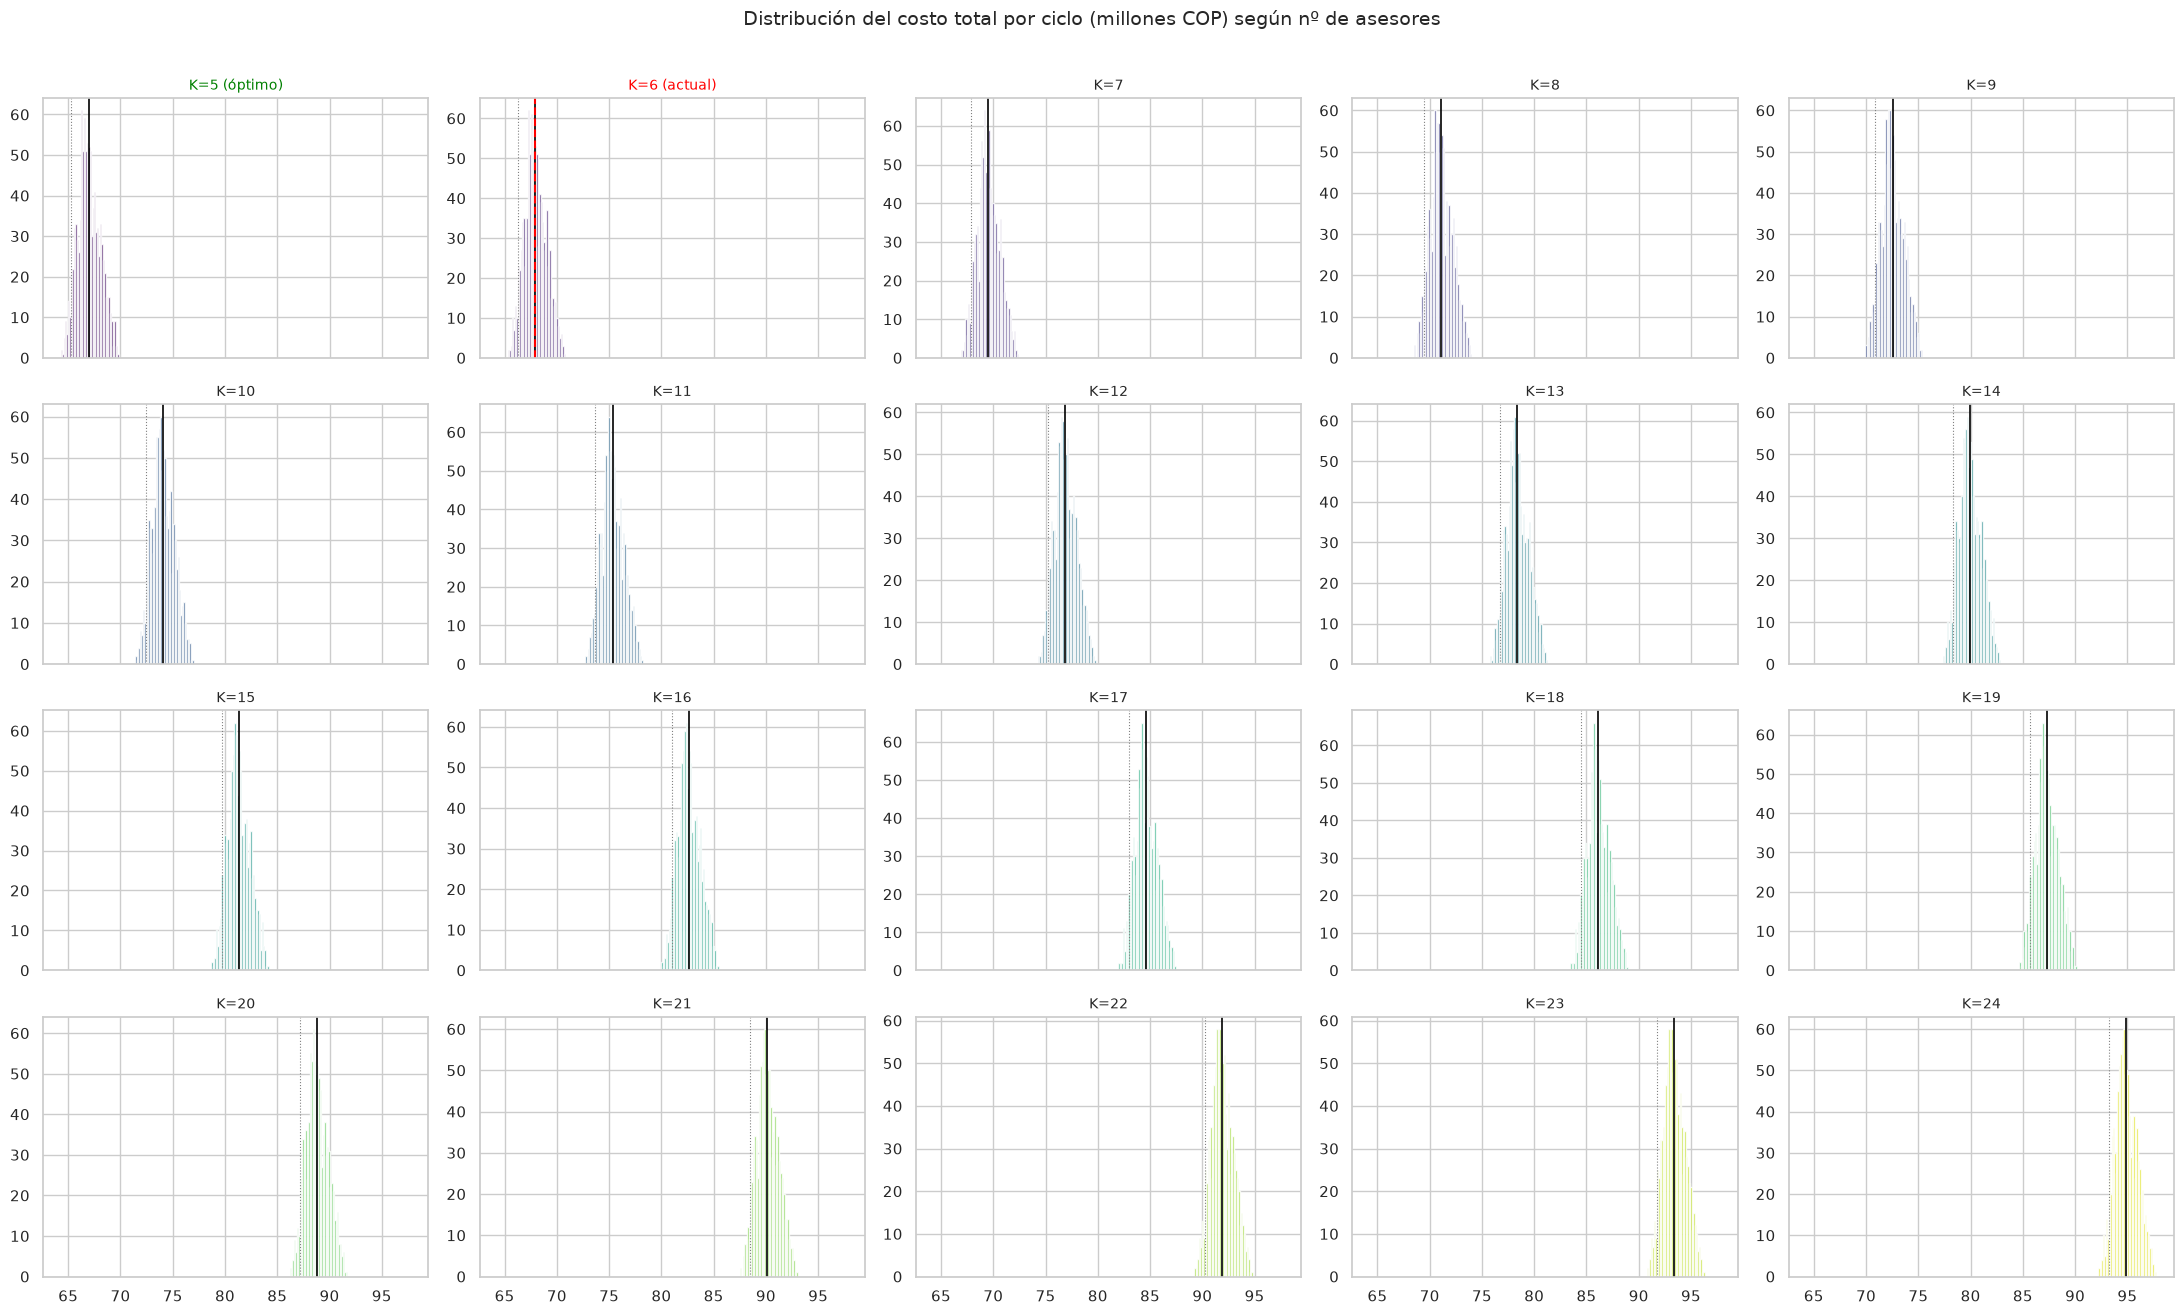

In [11]:
ks = sorted(estrategias)
fig, axes = plt.subplots(4, 5, figsize=(22, 13), sharex=True)
for ax, K in zip(axes.flat, ks):
    v = COSTO[K] / 1e6
    ax.hist(v, bins=40, color=sns.color_palette("viridis", 20)[K - K_MIN], alpha=0.85)
    ax.axvline(v.mean(), color="black", lw=1.2)
    if K == 6:
        ax.axvline(v.mean(), color="red", lw=1.5, ls="--")
        ax.set_title(f"K={K} (actual)", fontsize=10, color="red")
    elif K == best:
        ax.set_title(f"K={K} (óptimo)", fontsize=10, color="green")
    else:
        ax.set_title(f"K={K}", fontsize=10)
    ax.axvline(np.percentile(v, 5), color="gray", lw=0.8, ls=":")
fig.suptitle("Distribución del costo total por ciclo (millones COP) según nº de asesores", y=1.01, fontsize=14)
plt.tight_layout()
plt.show()

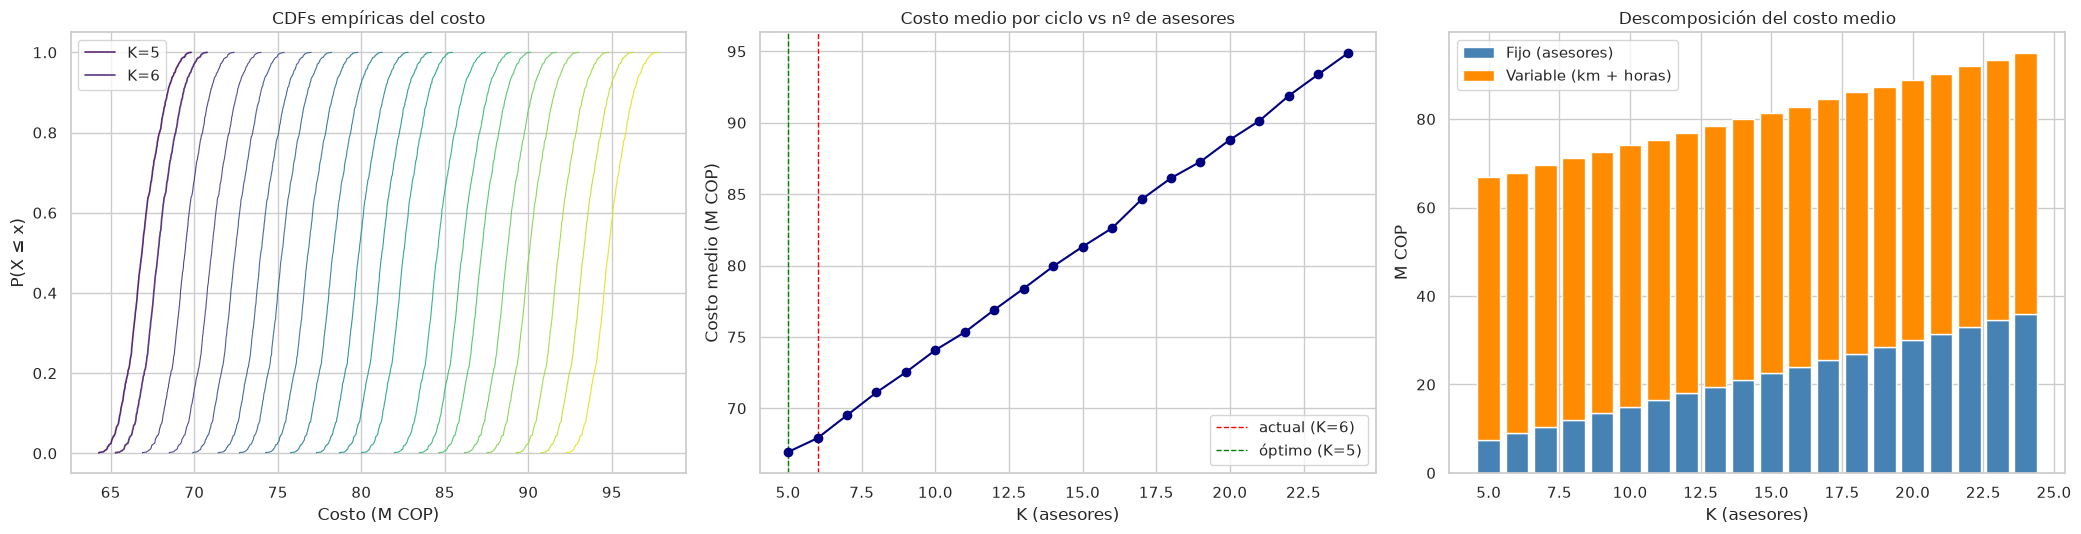

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(21, 5.5))

# (a) CDFs
ax = axes[0]
color = sns.color_palette("viridis", len(ks))
for i, K in enumerate(ks):
    x = np.sort(COSTO[K].to_numpy() / 1e6)
    ax.plot(x, np.arange(1, len(x) + 1) / len(x), lw=1.2 if K in (6, best) else 0.8,
            color=color[i], alpha=0.9, label=f"K={K}" if K in (6, best) else None)
ax.set_title("CDFs empíricas del costo"); ax.set_xlabel("Costo (M COP)"); ax.set_ylabel("P(X ≤ x)")
ax.legend()

# (b) Costo medio vs K con IC95
ax = axes[1]
med = tabla["Costo medio"]; ic = 1.96 * COSTO.std(ddof=1) / np.sqrt(N_SIM) / 1e6
ax.errorbar(med.index, med.values, yerr=ic.values, fmt="o-", color="navy", capsize=3)
ax.axvline(6, color="red", ls="--", lw=1, label="actual (K=6)")
ax.axvline(best, color="green", ls="--", lw=1, label=f"óptimo (K={best})")
ax.set_title("Costo medio por ciclo vs nº de asesores"); ax.set_xlabel("K (asesores)")
ax.set_ylabel("Costo medio (M COP)"); ax.legend()

# (c) Descomposición fijo vs variable
ax = axes[2]
fijo = np.array([K * COSTO_ASESOR for K in ks]) / 1e6
variable = med.values - fijo
ax.bar(ks, fijo, label="Fijo (asesores)", color="steelblue")
ax.bar(ks, variable, bottom=fijo, label="Variable (km + horas)", color="darkorange")
ax.set_title("Descomposición del costo medio"); ax.set_xlabel("K (asesores)")
ax.set_ylabel("M COP"); ax.legend()

plt.tight_layout()
plt.show()

## 11. Convergencia, sensibilidad y robustez

- **Convergencia (LGN):** la media acumulada del costo debe estabilizarse.
- **Sensibilidad:** correlación de Spearman entre las variables inciertas (tasa de asistencia
  realizada y factor de tráfico del escenario) y el costo; la contribución a la varianza
  es proporcional a $\rho^2$.
- **Robustez:** el ranking de estrategias se re-verifica variando $p$ de asistencia y el rango
  de tráfico.

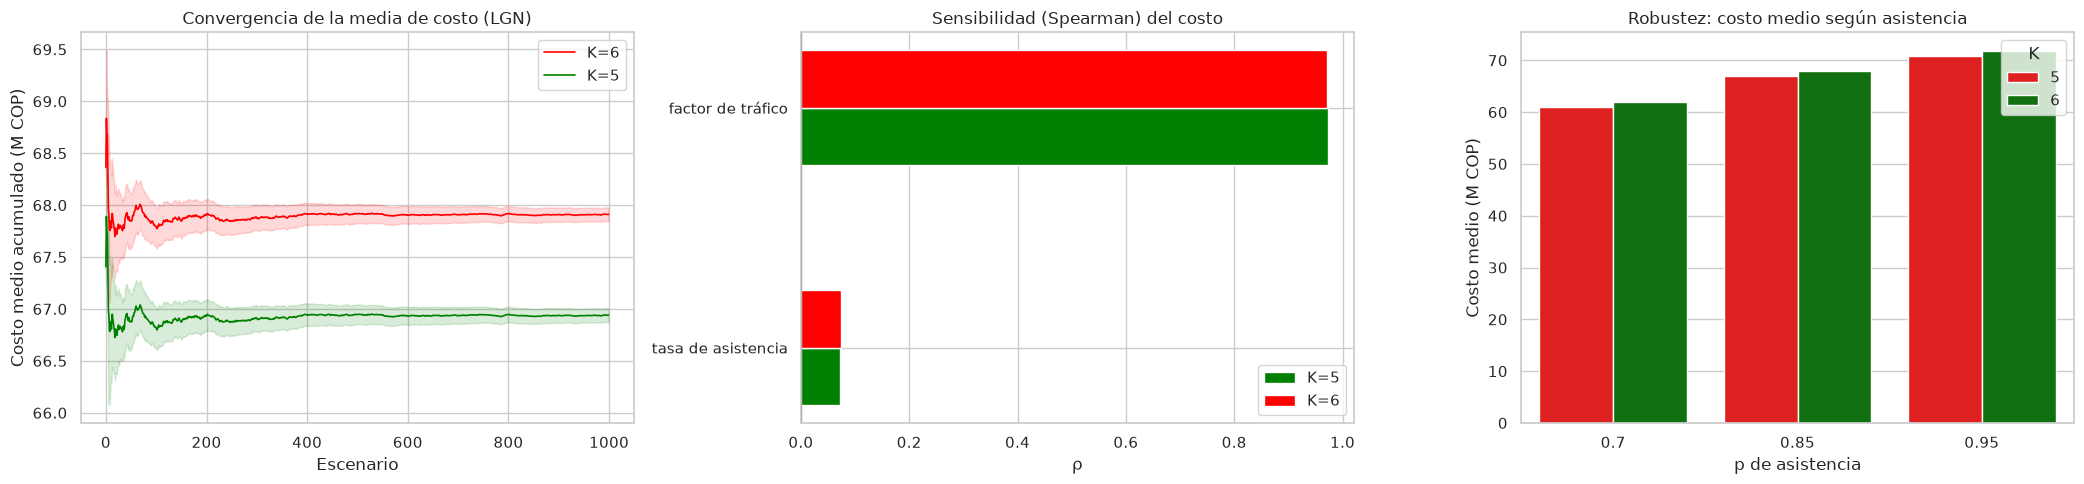

,p_asistencia,K,costo
0,0.700000,6,61.9
1,0.700000,5,61.0
2,0.850000,6,67.9
3,0.850000,5,66.9
4,0.950000,6,71.8
5,0.950000,5,70.8


In [13]:
fig, axes = plt.subplots(1, 3, figsize=(21, 5))

# (a) Convergencia
ax = axes[0]
for K, c in [(6, "red"), (best, "green")]:
    v = COSTO[K].to_numpy() / 1e6
    media = np.cumsum(v) / np.arange(1, len(v) + 1)
    ee = np.cumsum(v**2) / np.arange(1, len(v) + 1) - media**2
    ee = np.sqrt(np.maximum(ee, 0) / np.arange(1, len(v) + 1))
    ax.plot(media, color=c, lw=1.2, label=f"K={K}")
    ax.fill_between(np.arange(len(v)), media - 1.96*ee, media + 1.96*ee, color=c, alpha=0.15)
ax.set_title("Convergencia de la media de costo (LGN)"); ax.set_xlabel("Escenario")
ax.set_ylabel("Costo medio acumulado (M COP)"); ax.legend()

# (b) Tornado de sensibilidad (Spearman) para la estrategia óptima y la actual
ax = axes[1]
tasa_real = asistencia.mean(axis=1)                    # tasa de asistencia del escenario
entradas = {"tasa de asistencia": tasa_real, "factor de tráfico": trafico}
for K, off in [(best, -0.12), (6, 0.12)]:
    rhos = [stats.spearmanr(x, COSTO[K].to_numpy())[0] for x in entradas.values()]
    ax.barh(np.arange(len(entradas)) + off, rhos, height=0.24,
            color="green" if K == best else "red", label=f"K={K}")
ax.axvline(0, color="black", lw=0.8)
ax.set_yticks(range(len(entradas))); ax.set_yticklabels(list(entradas))
ax.set_title("Sensibilidad (Spearman) del costo"); ax.set_xlabel("ρ"); ax.legend()

# (c) Robustez: costo medio variando p de asistencia y tráfico
ax = axes[2]
rob = []
for p in [0.70, 0.85, 0.95]:
    asis_p = np.random.default_rng(SEMILLA + 1).random(asistencia.shape) < p
    for K in [6, best]:
        ev = evaluar_estrategia(estrategias[K][0], asis_p, trafico)
        rob.append(dict(p_asistencia=p, K=K,
                        costo=(ev["variable"].mean() + K * COSTO_ASESOR) / 1e6))
rob = pd.DataFrame(rob)
sns.barplot(data=rob, x="p_asistencia", y="costo", hue="K", ax=ax, palette=["red", "green"])
ax.set_title("Robustez: costo medio según asistencia"); ax.set_ylabel("Costo medio (M COP)")
ax.set_xlabel("p de asistencia")
plt.tight_layout()
plt.show()
display(rob.style.format({"costo": "{:,.1f}"}))

## 12. Comparación pareada y decisión

Diferencias de costo por escenario entre cada estrategia y el escenario actual (**K=6**),
con intervalo de confianza al 95 % y probabilidad de ser mejor (números aleatorios comunes).

In [14]:
base_col = COSTO[6].to_numpy()
filas = []
for K in ks:
    d = (COSTO[K].to_numpy() - base_col) / 1e6          # M COP, por escenario
    ee = d.std(ddof=1) / np.sqrt(len(d))
    filas.append({"K": K, "dif_media": d.mean(), "ic95_inf": d.mean() - 1.96*ee,
                  "ic95_sup": d.mean() + 1.96*ee,
                  "P(mejor_que_actual)": (d < 0).mean()})
pareada = pd.DataFrame(filas).set_index("K")
display(pareada.style.format({"dif_media": "{:,.2f}", "ic95_inf": "{:,.2f}",
                              "ic95_sup": "{:,.2f}", "P(mejor_que_actual)": "{:.1%}"})
        .background_gradient(subset=["dif_media"], cmap="RdYlGn_r"))

mejor_fijo = int(tabla["Costo medio"].idxmin())
mejor_variable = int((tabla["Costo medio"] - np.array([K*COSTO_ASESOR for K in tabla.index])/1e6).idxmin())
print(f"Menor costo TOTAL:        K = {mejor_fijo}")
print(f"Menor costo VARIABLE:     K = {mejor_variable} (km + horas, sin el fijo de asesores)")
print(f"Balance más equilibrado:  K = {int(tabla['balance CV'].idxmin())} (menor CV de carga)")

,dif_media,ic95_inf,ic95_sup,P(mejor_que_actual)
K,,,,
5,-0.97,-0.97,-0.97,100.0%
6,0.00,0.00,0.00,0.0%
7,1.60,1.60,1.60,0.0%
8,3.20,3.20,3.20,0.0%
9,4.61,4.61,4.62,0.0%
10,6.16,6.16,6.17,0.0%
11,7.42,7.42,7.42,0.0%
12,8.98,8.98,8.99,0.0%
13,10.48,10.47,10.48,0.0%


Menor costo TOTAL:        K = 5
Menor costo VARIABLE:     K = 16 (km + horas, sin el fijo de asesores)
Balance más equilibrado:  K = 21 (menor CV de carga)


## 13. Conclusiones y limitaciones

### Resultados (supuestos base, 1.000 escenarios)

1. **El costo total mínimo es K = 5** (66,9 M COP/ciclo): ahorra ≈ 1,0 M (~1,4 %) frente al
   actual K = 6, con IC95 que no cruza cero y menor costo en el **100 % de los escenarios**
   (comparación pareada, números aleatorios comunes).
2. **El costo variable es prácticamente plano en K.** Los km quedan en una banda estrecha de
   ≈ 17.700–18.500 km (±2 %) para cualquier número de asesores: **el número de asesores casi no
   cambia la eficiencia de las rutas**, porque las sub-rutas las determina la capacidad
   (45 visitas/día) y la geografía; más asesores solo *reparten* el mismo territorio.
   El óptimo de costo variable ocurre en K = 16 (17.677 km), pero su ahorro (~500 km ≈ 0,6 M)
   no compensa ni un asesor adicional (1,5 M).
3. Por tanto, **la decisión la domina el costo fijo** (+1,5 M COP/ciclo por asesor): cada
   asesor adicional debe justificarse por servicio o equidad, no por ahorro de km.
4. **Trade-off con el balance de carga:** K = 5 es el más desbalanceado (CV = 2,00; un solo
   asesor absorbería los ≈ 8.400 clientes de AV06) y K = 6 baja el CV a 1,46. El mejor balance
   está en K = 21 (CV = 1,30), pero a un costo ≈ 23 M COP/ciclo mayor.
5. **Robustez:** el orden K = 5 < K = 6 en costo se mantiene con asistencias de 70 %, 85 % y 95 %.

### Recomendación
Mantenerse en el rango **K = 5–7**. Con criterio puramente de costo, **K = 5**; si la empresa
valora el balance de carga (recomendado, dado el CV de AV06), **K = 6 —el actual— ya está casi
en el óptimo**: el "exceso" cuesta ≈ 1 M COP/ciclo (≈ 2 M/mes) y se justifica si mejora la
cobertura y la equidad. **No se justifican más de 8 asesores**: el costo crece lineal mientras
los km no mejoran.

### Limitaciones del modelo
1. **Costos supuestos:** $c_{\text{asesor}}$, $c_{\text{km}}$ y $c_{\text{hora}}$ son parámetros del
   equipo; calibrarlos con la empresa cambia el nivel (no el patrón) del óptimo.
2. **NN en vez de ACO:** el NN es ~2,3 % peor que el ACO del modelo de ruteo; como el mismo motor
   se aplica a todas las estrategias, el **ranking** es robusto, aunque el nivel de km es levemente
   optimista en la práctica.
3. **Depósito aproximado** con el centroide del CD (la base no trae las coordenadas exactas):
   infla el nivel absoluto de km (~43 % sobre el modelo), pero de forma común a todas las estrategias.
4. **Asistencia i.i.d.** con la misma $p$ para todos los clientes; en la práctica varía por
   municipio, categoría y estación.
5. **Un solo periodo** (ciclo de rutero); no modela crecimiento de cartera ni rotación de asesores.
6. La **asignación proporcional** de asesores a CDs es una regla simple; el balance real podría
   requerir ajustes por esfuerzo (ruralidad, tiempos), no solo por número de clientes.

**Siguiente paso sugerido:** calibrar costos y $p$ con la operación, y re-ejecutar; si el
negocio considera restricciones adicionales (por ejemplo, cupo máximo de asesores o una carga
máxima por asesor), agregarlas como filtro de estrategias factibles.